<a href="https://colab.research.google.com/github/dogematos2-sudo/projeto-dados-olist/blob/main/analise_dados_olist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto de Análise Exploratória de Dados (EDA) - Olist E-Commerce

Este notebook contém a análise de dados públicos de e-commerce da Olist. O objetivo é extrair insights acionáveis sobre vendas, comportamento do cliente e distribuição geográfica.

## 🛠️ Etapas do Projeto

1. **Carga dos Dados**:
   * Leitura das tabelas de pedidos (`orders`), itens (`order_items`) e clientes (`customers`).

2. **Distribuição Geográfica de Clientes**:
   * Análise de concentração de clientes únicos por estado brasileiro. Descobrimos que **São Paulo (SP)** concentra cerca de **41,9%** de todos os clientes do dataset.

3. **Faturamento por Estado**:
   * Cruzamento de tabelas para somar o valor dos produtos vendidos e correlacionar com a localização do cliente. Confirmamos que **SP foca ~38,3% do faturamento total**.

4. **Evolução Temporal e Sazonalidade**:
   * Agrupamento mensal das vendas para identificar picos históricos, destacando o impacto de eventos como a **Black Friday (Novembro/2017)**.

# 🎓 Guia de Estudo: Entendendo o nosso Código Passo a Passo

Para apresentar ou explicar esse projeto para outras pessoas (ou em entrevistas de emprego), você pode usar este roteiro simplificado de como cada trecho de código funciona:

---

### 1. Carregando os Dados (`pd.read_csv`)
```python
orders_df = pd.read_csv('/content/olist_orders_dataset.csv')
```
* **O que faz?** O Pandas é a biblioteca que usamos para ler tabelas. O método `read_csv` abre o arquivo `.csv` e o transforma em um **DataFrame** (que você pode imaginar simplesmente como uma planilha do Excel dentro do Python).

---

### 2. Cruzando Tabelas (`.merge`)
```python
merged_df = order_items_df.merge(orders_df, on='order_id').merge(customers_df, on='customer_id')
```
* **O que faz?** No banco de dados da Olist, as informações estão separadas em várias planilhas para economizar espaço. Para saber de qual estado veio uma venda, precisamos juntar essas tabelas:
  * Pegamos os itens vendidos (`order_items_df`) e juntamos com as informações do pedido (`orders_df`) através do código identificador do pedido (`order_id`).
  * Depois, juntamos esse resultado com a planilha de clientes (`customers_df`) usando o identificador do cliente (`customer_id`).
* **Análogo no Excel:** É exatamente igual a usar a fórmula `PROCV` (VLOOKUP) para trazer dados de uma planilha para outra.

---

### 3. Agrupando e Somando Valores (`.groupby` e `.sum`)
```python
state_revenue = merged_df.groupby('customer_state')['price'].sum()
```
* **O que faz?** O `groupby` divide os dados em grupos com base em uma coluna (neste caso, o estado do cliente `customer_state`). O `['price'].sum()` diz para o Python somar todos os valores de preço dos produtos pertencentes a cada um desses estados.
* **Análogo no Excel:** Funciona igualzinho a uma **Tabela Dinâmica** onde você arrasta os "Estados" para as linhas e a "Soma de Preço" para os valores.

---

### 4. Trabalhando com Datas (`pd.to_datetime` e `to_period`)
```python
merged_df['order_purchase_timestamp'] = pd.to_datetime(merged_df['order_purchase_timestamp'])
merged_df['ano_mes'] = merged_df['order_purchase_timestamp'].dt.to_period('M')
```
* **O que faz?** Por padrão, o Python lê datas como textos comuns. A primeira linha converte esse texto em uma **data real**, permitindo cálculos. A segunda linha extrai apenas o **Ano e o Mês** (por exemplo, transforma `2017-11-24 15:30:00` em apenas `2017-11`), o que facilita agrupar as vendas mensalmente.

### 5. Traduzindo do Pandas para o SQL

No dia a dia de um **Analytics Engineer**, traduzir lógicas de Python (Pandas) para SQL é extremamente comum. Veja como a nossa consulta se compara à lógica do Pandas:

* **No Pandas (`merge`)** = **No SQL (`INNER JOIN`)**:
  ```sql
  FROM order_items oi
  INNER JOIN orders o ON oi.order_id = o.order_id
  INNER JOIN customers c ON o.customer_id = c.customer_id
  ```
  *Conectamos as tabelas usando chaves comuns (como códigos de pedidos e códigos de clientes).*

* **No Pandas (`groupby`)** = **No SQL (`GROUP BY`)**:
  ```sql
  GROUP BY c.customer_state
  ```
  *Gera as divisões por estados.*

* **No Pandas (`sum`)** = **No SQL (`SUM(price)`)**:
  ```sql
  ROUND(SUM(oi.price), 2) AS Faturamento_Total
  ```
  *Soma os valores e formata o resultado com 2 casas decimais.*

In [ ]:
import pandas as pd

# Carregando os principais datasets
orders_df = pd.read_csv('/content/olist_orders_dataset.csv')
order_items_df = pd.read_csv('/content/olist_order_items_dataset.csv')
customers_df = pd.read_csv('/content/olist_customers_dataset.csv')

# Exibindo as primeiras linhas de cada um para inspeção
print("--- Pedidos (Orders) ---")
display(orders_df.head())

print("\n--- Itens dos Pedidos (Order Items) ---")
display(order_items_df.head())

print("\n--- Clientes (Customers) ---")
display(customers_df.head())

--- Pedidos (Orders) ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



--- Itens dos Pedidos (Order Items) ---


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



--- Clientes (Customers) ---


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


--- Top 10 Estados com mais clientes únicos ---


,Estado,Clientes Únicos,Porcentagem (%)
0,SP,40302,41.92
1,RJ,12384,12.88
2,MG,11259,11.71
3,RS,5277,5.49
4,PR,4882,5.08
5,SC,3534,3.68
6,BA,3277,3.41
7,DF,2075,2.16
8,ES,1964,2.04
9,GO,1952,2.03


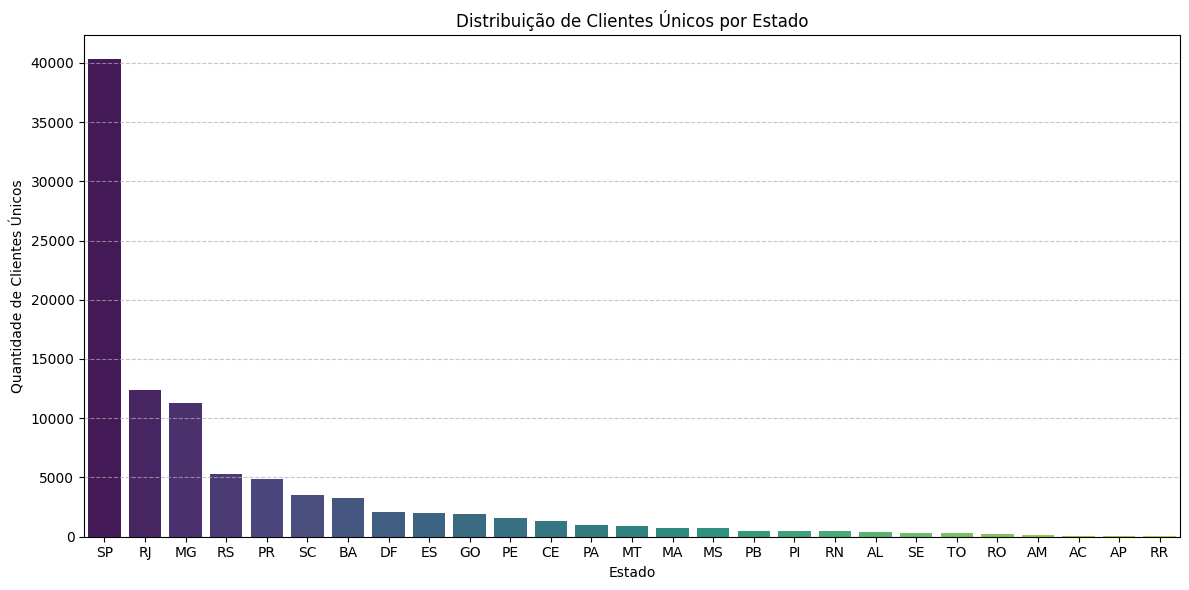

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Agrupando os clientes únicos por estado
state_counts = customers_df.groupby('customer_state')['customer_unique_id'].nunique().sort_values(ascending=False).reset_index()
state_counts.columns = ['Estado', 'Clientes Únicos']

# Calculando a porcentagem
total_customers = state_counts['Clientes Únicos'].sum()
state_counts['Porcentagem (%)'] = (state_counts['Clientes Únicos'] / total_customers * 100).round(2)

print("--- Top 10 Estados com mais clientes únicos ---")
display(state_counts.head(10))

# Plotando o gráfico de distribuição geográfica
plt.figure(figsize=(12, 6))
sns.barplot(x='Estado', y='Clientes Únicos', data=state_counts, palette='viridis', hue='Estado', legend=False)
plt.title('Distribuição de Clientes Únicos por Estado')
plt.xlabel('Estado')
plt.ylabel('Quantidade de Clientes Únicos')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

--- Top 10 Estados em Faturamento Total ---


,Estado,Faturamento Total (R$),Porcentagem (%)
0,SP,5202955.05,38.28
1,RJ,1824092.67,13.42
2,MG,1585308.03,11.66
3,RS,750304.02,5.52
4,PR,683083.76,5.03
5,SC,520553.34,3.83
6,BA,511349.99,3.76
7,DF,302603.94,2.23
8,GO,294591.95,2.17
9,ES,275037.31,2.02


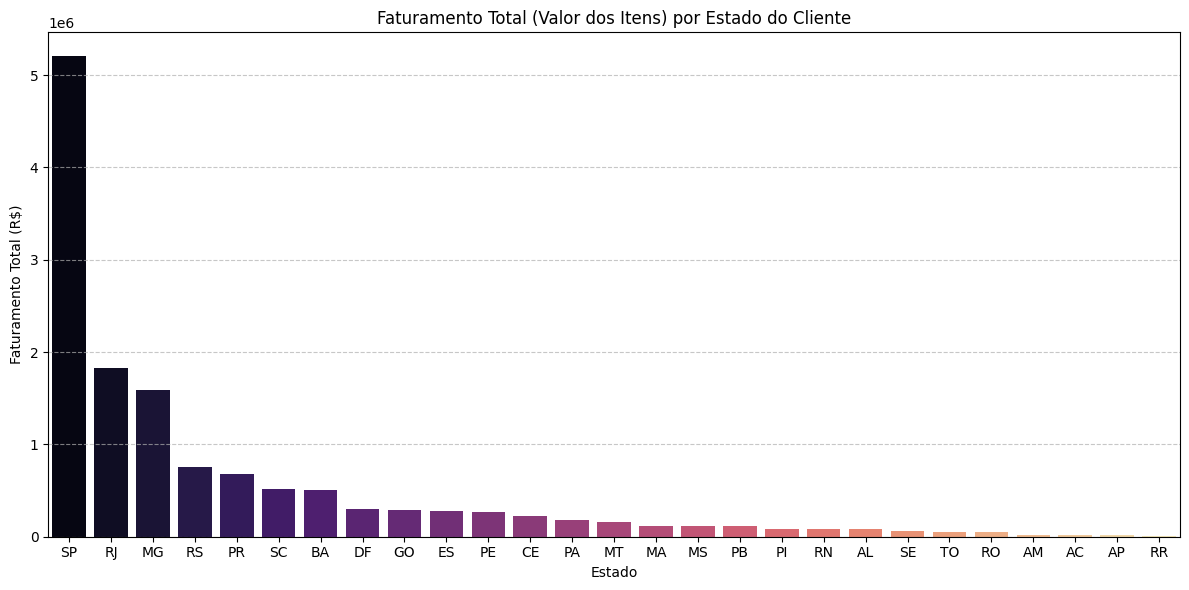

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mesclando as tabelas para associar o valor gasto ao estado do cliente
# orders_df -> customers_df (via customer_id)
# order_items_df -> orders_df (via order_id)
merged_df = order_items_df.merge(orders_df, on='order_id').merge(customers_df, on='customer_id')

# Agrupando o faturamento (soma do preço dos itens) por estado
state_revenue = merged_df.groupby('customer_state')['price'].sum().sort_values(ascending=False).reset_index()
state_revenue.columns = ['Estado', 'Faturamento Total (R$)']

# Calculando a porcentagem do faturamento de cada estado
total_revenue = state_revenue['Faturamento Total (R$)'].sum()
state_revenue['Porcentagem (%)'] = (state_revenue['Faturamento Total (R$)'] / total_revenue * 100).round(2)

print("--- Top 10 Estados em Faturamento Total ---")
display(state_revenue.head(10))

# Plotando o gráfico de faturamento por estado
plt.figure(figsize=(12, 6))
sns.barplot(x='Estado', y='Faturamento Total (R$)', data=state_revenue, palette='magma', hue='Estado', legend=False)
plt.title('Faturamento Total (Valor dos Itens) por Estado do Cliente')
plt.xlabel('Estado')
plt.ylabel('Faturamento Total (R$)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

--- Faturamento Mensal Histórico ---


,ano_mes,price,ano_mes_dt
0,2016-09,267.36,2016-09-01
1,2016-10,49507.66,2016-10-01
2,2016-12,10.90,2016-12-01
3,2017-01,120312.87,2017-01-01
4,2017-02,247303.02,2017-02-01
5,2017-03,374344.30,2017-03-01
6,2017-04,359927.23,2017-04-01
7,2017-05,506071.14,2017-05-01
8,2017-06,433038.60,2017-06-01
9,2017-07,498031.48,2017-07-01


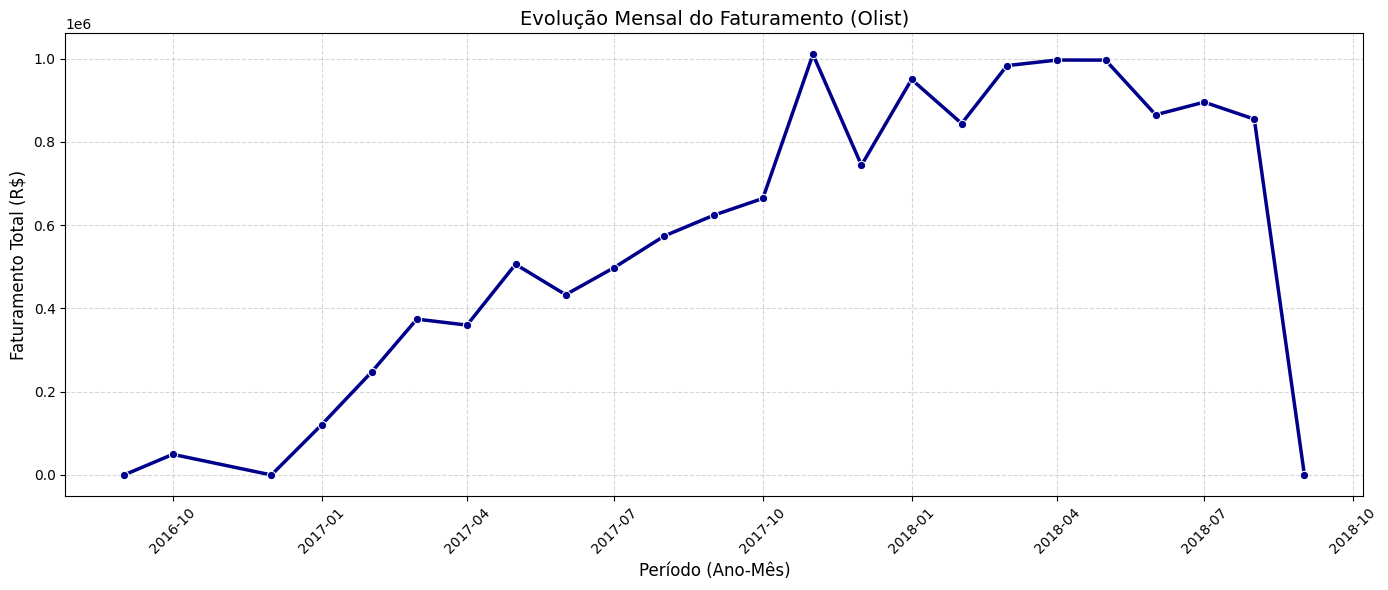

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Garantir que as datas estejam no formato correto datetime
merged_df['order_purchase_timestamp'] = pd.to_datetime(merged_df['order_purchase_timestamp'])

# 2. Criar uma coluna com o Período (Ano-Mês)
merged_df['ano_mes'] = merged_df['order_purchase_timestamp'].dt.to_period('M')

# 3. Agrupar o faturamento por Ano-Mês
monthly_revenue = merged_df.groupby('ano_mes')['price'].sum().reset_index()

# Converter de volta para datetime apenas para facilitar a plotagem no gráfico
monthly_revenue['ano_mes_dt'] = monthly_revenue['ano_mes'].dt.to_timestamp()

# Exibindo a tabela com o faturamento mensal
print("--- Faturamento Mensal Histórico ---")
display(monthly_revenue.sort_values('ano_mes'))

# 4. Plotando a evolução temporal do faturamento
plt.figure(figsize=(14, 6))
sns.lineplot(x='ano_mes_dt', y='price', data=monthly_revenue, marker='o', color='darkblue', linewidth=2.5)
plt.title('Evolução Mensal do Faturamento (Olist)', fontsize=14)
plt.xlabel('Período (Ano-Mês)', fontsize=12)
plt.ylabel('Faturamento Total (R$)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 🗄️ Fase 2: Transição e Análise Usando SQL (Engenharia de Analytics)

Para demonstrar versatilidade técnica no portfólio, nesta etapa vamos migrar nossos dados estruturados para um banco de dados relacional embutido (**SQLite**) e realizar análises utilizando consultas SQL nativas.

In [ ]:
import sqlite3

# 1. Criando uma conexão com um banco de dados SQLite local (em arquivo)
conn = sqlite3.connect('olist_database.db')

# 2. Salvando os DataFrames do Pandas como tabelas SQL
# Se as tabelas já existirem, elas serão substituídas (if_exists='replace')
orders_df.to_sql('orders', conn, if_exists='replace', index=False)
order_items_df.to_sql('order_items', conn, if_exists='replace', index=False)
customers_df.to_sql('customers', conn, if_exists='replace', index=False)

print("Tabelas criadas com sucesso no SQLite!")
# Confirmando as tabelas existentes no banco
cursor = conn.cursor()
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
print("Tabelas disponíveis no banco:", cursor.fetchall())

Tabelas criadas com sucesso no SQLite!
Tabelas disponíveis no banco: [('orders',), ('order_items',), ('customers',)]


### Executando nossa primeira Query SQL de Negócios

Vamos recriar a análise de faturamento por estado utilizando a sintaxe padrão do SQL (ANSI SQL), simulando o dia a dia de um engenheiro de dados lidando com data warehouses.

In [ ]:
# Query SQL para calcular faturamento acumulado por estado dos clientes
query = """
SELECT
    c.customer_state AS Estado,
    ROUND(SUM(oi.price), 2) AS Faturamento_Total,
    ROUND((SUM(oi.price) / (SELECT SUM(price) FROM order_items) * 100), 2) AS Porcentagem
FROM order_items oi
INNER JOIN orders o ON oi.order_id = o.order_id
INNER JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.customer_state
ORDER BY Faturamento_Total DESC
LIMIT 10;
"""

# Executando a consulta e carregando o resultado de volta para exibição
df_sql_result = pd.read_sql_query(query, conn)
display(df_sql_result)

,Estado,Faturamento_Total,Porcentagem
0,SP,5202955.05,38.28
1,RJ,1824092.67,13.42
2,MG,1585308.03,11.66
3,RS,750304.02,5.52
4,PR,683083.76,5.03
5,SC,520553.34,3.83
6,BA,511349.99,3.76
7,DF,302603.94,2.23
8,GO,294591.95,2.17
9,ES,275037.31,2.02


# 📊 Fase 3: Preparação dos Arquivos para o Power BI

Vamos exportar nossas duas tabelas calculadas em formato `.csv` para que você possa fazer o download delas pela barra lateral esquerda do Colab e importá-las diretamente no Power BI.

In [ ]:
# 1. Exportando a análise de Faturamento por Estado
state_revenue.to_csv('faturamento_por_estado.csv', index=False)

# 2. Convertendo o período para texto e salvando a Evolução Mensal
monthly_export = monthly_revenue.copy()
monthly_export['ano_mes'] = monthly_export['ano_mes'].astype(str)
monthly_export.to_csv('faturamento_mensal.csv', index=False)

print("Arquivos prontos para o Power BI!")
print("- faturamento_por_estado.csv")
print("- faturamento_mensal.csv")
print("\n💡 Dica: Clique no ícone de pasta (📁) na lateral esquerda do Colab para baixar os arquivos.")

Arquivos prontos para o Power BI!
- faturamento_por_estado.csv
- faturamento_mensal.csv

💡 Dica: Clique no ícone de pasta (📁) na lateral esquerda do Colab para baixar os arquivos.


## 🗺️ Como construir os Visuais no Power BI

Depois de baixar os arquivos `.csv` acima, siga este roteiro no seu Power BI:

### 1. Importar os Dados
1. Abra o **Power BI Desktop**.
2. No menu inicial, clique em **Obter Dados** (Get Data) > **Texto/CSV**.
3. Selecione o arquivo `faturamento_por_estado.csv` e clique em **Carregar**.
4. Repita o processo para o arquivo `faturamento_mensal.csv`.

### 2. Criar o Visual 1: Faturamento por Estado (Gráfico de Barras)
1. Na barra lateral direita, selecione a tabela `faturamento_por_estado`.
2. Escolha o visual de **Gráfico de barras clusterizadas** (Horizontal ou Vertical).
3. Arraste o campo `Estado` para o **Eixo Y**.
4. Arraste o campo `Faturamento Total (R$)` para os **Valores**.

### 3. Criar o Visual 2: Linha de Sazonalidade (Gráfico de Linha)
1. Selecione a tabela `faturamento_mensal`.
2. Escolha o visual de **Gráfico de linhas**.
3. Arraste o campo `ano_mes_dt` para o **Eixo X**.
4. Arraste o campo `price` (Faturamento) para o **Eixo Y**.

*Pronto! Você terá uma tela dinâmica com a distribuição geográfica e a curva histórica mostrando o pico de faturamento da Black Friday.*